In [24]:

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from sqlalchemy import create_engine
import urllib

In [25]:



# 1. تحديد اسم السيرفر واسم قاعدة البيانات
server = 'NOUR'
database = 'RetailDWH'


# 2. Windows Authentication
params = urllib.parse.quote_plus(
    f"DRIVER={{ODBC Driver 17 for SQL Server}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    f"Trusted_Connection=yes;"
)

# 3. فتح الاتصال وسحب الداتا
engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")
# fact 
fact = pd.read_sql(f"select * from fact_date ", engine)
# dim
customer = pd.read_sql(f"select * from customer_dim ", engine)
store = pd.read_sql(f"select * from store_dim ", engine)
trans = pd.read_sql(f"select * from trans_dim ", engine)
items = pd.read_sql(f"select * from item_dim ", engine)





In [26]:
fact_all = pd.read_sql(f"select * from fact_table ", engine)
fact_df1 = pd.DataFrame(fact_all)

In [27]:
# trans to data frame 
fact_df = pd.DataFrame(fact)
customer_df = pd.DataFrame(customer)
store_df = pd.DataFrame(store)
trans_df = pd.DataFrame(trans)
items_df = pd.DataFrame(items)

total amount in fact table : 105.40143575     MILLION
<class 'pandas.DataFrame'>
Index: 1000000 entries, 575883 to 156762
Data columns (total 7 columns):
 #   Column        Non-Null Count    Dtype        
---  ------        --------------    -----        
 0   fact_id       1000000 non-null  str          
 1   date          1000000 non-null  datetime64[s]
 2   unit          1000000 non-null  str          
 3   quantity      1000000 non-null  float64      
 4   unit_price    1000000 non-null  float64      
 5   total_amount  1000000 non-null  object       
 6   date_quarter  1000000 non-null  period[Q-DEC]
dtypes: datetime64[s](1), float64(2), object(1), period[Q-DEC](1), str(2)
memory usage: 61.0+ MB
None
fact_id         1000000
date               2561
unit                 13
quantity             11
unit_price           46
total_amount        285
date_quarter         32
dtype: int64
<StringArray>
['bottles',      'ct',    'bags',    'cans',      'pk',    'tubs',      'oz',
   'rolls', 

C:\Users\nourz\AppData\Local\Temp\ipykernel_18836\2422198782.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=fact_df,x='unit',y='total_amount',palette='Set1',showfliers=False)


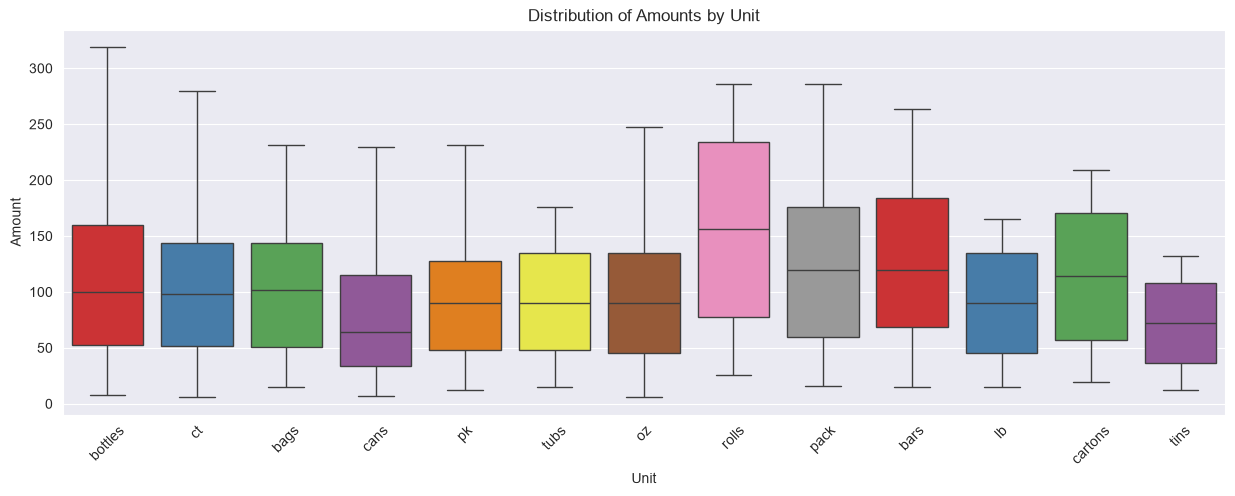

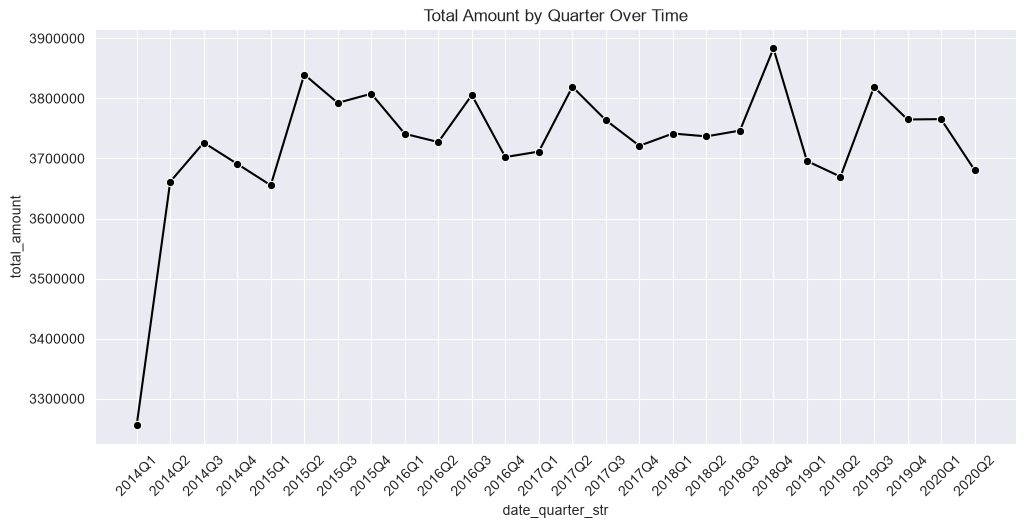

In [32]:
# EDA fact 
from datetime import datetime
print('total amount in fact table : ' + str(fact_df['total_amount'].sum()/1000000) + '     MILLION')

print(fact_df.info())
# handle missing values
fact_df.dropna(subset=['fact_id'],inplace=True)
fact_df.isnull().sum()
print(fact_df.nunique())
# change fact_id to string
fact_df['fact_id'] = fact_df['fact_id'].astype(str)
# replace duplicates
unit_mode = fact_df['unit'].mode()[0]
mapping = {
    'ct.': 'ct',
    'oz.': 'oz',
    'bags': 'bags',
    'botlltes': 'bottles',
    'Bags': 'bags' ,
    'Ct' : 'ct' ,
    '' : unit_mode
}
fact_df['unit'] = fact_df['unit'].replace(mapping)
print(fact_df['unit'].unique())
# visualize the distribution of total amounts by unit
  #handle date column
fact_df['date'] = pd.to_datetime(fact_df['date'])
fact_df['date_quarter'] = fact_df['date'].dt.to_period('Q')
quarterly_data = fact_df.groupby('date_quarter')['total_amount'].sum().reset_index()
quarterly_data['date_quarter_str'] = quarterly_data['date_quarter'].astype(str)
fact_df.sort_values(by='date_quarter', inplace=True)
  # Calculate missing total amounts
fact_df['total_amount'] = fact_df['total_amount'].fillna(
  fact_df['quantity'] * fact_df['unit_price']
)

  # visualize the distribution of total amounts by unit
plt.figure(figsize=(15, 5))
sns.boxplot(data=fact_df,x='unit',y='total_amount',palette='Set1',showfliers=False)
plt.xlabel('Unit')
plt.ylabel('Amount')
plt.title('Distribution of Amounts by Unit')
plt.xticks(rotation=45)
  # visualize the trend of total amounts over time by quarter
cleaned_quarterly_data = quarterly_data[quarterly_data['date_quarter_str'] < '2020Q3']
sns.relplot(x='date_quarter_str', y='total_amount', data=cleaned_quarterly_data, kind='line', aspect=2, marker='o', color='black')
sns.set_style('darkgrid')
plt.title('Total Amount by Quarter Over Time')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')




<class 'pandas.DataFrame'>
RangeIndex: 9174 entries, 0 to 9173
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   customer_key  9174 non-null   str  
 1   name          9174 non-null   str  
 2   contact_no    9174 non-null   str  
 3   nid           9174 non-null   str  
dtypes: str(4)
memory usage: 286.8 KB
None
32037


C:\Users\nourz\AppData\Local\Temp\ipykernel_18420\2736977412.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='customer_segment', data=grouped_df, width=0.5,palette='Set1')
C:\Users\nourz\AppData\Local\Temp\ipykernel_18420\2736977412.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(y='total_amount',data=grouped_df,kind='box',showfliers=False,height=5,aspect=2,palette='Set1')


Text(0.5, 1.0, 'Distribution of Total Amounts by Customer Segment')

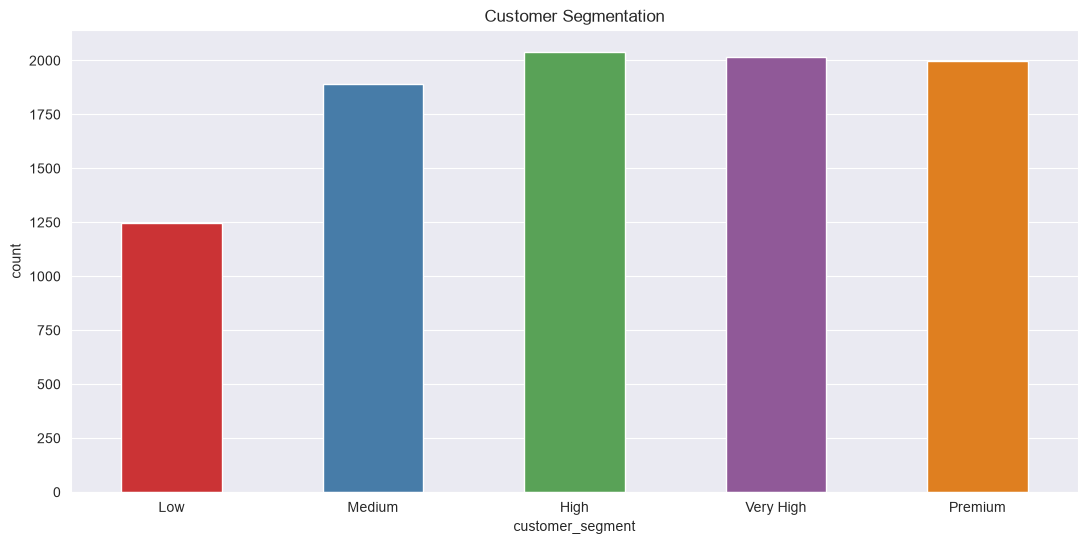

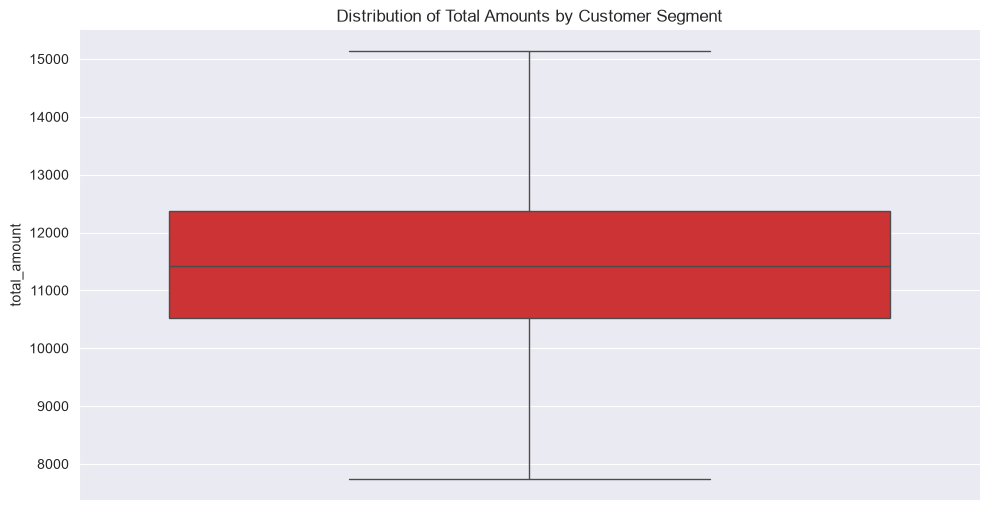

In [ ]:
# EDA customer
print(customer_df.info())
# handle missing values
customer_df.dropna(subset=['customer_key'], inplace=True)
customer_df.isnull().sum()
# count unique values
print(customer_df.nunique().sum())
# customer segmentation
grouped_df = fact_df1.groupby('coustomer_key', as_index=False)['total_amount'].sum()
grouped_df = grouped_df.rename(columns={'coustomer_key': 'customer_key'})
grouped_df['customer_frequency'] = grouped_df['customer_key'].map(fact_df1['coustomer_key'].value_counts())
grouped_df['frequency_score'] = pd.qcut(
    grouped_df['customer_frequency'],
    q=5,
    labels=[1, 2, 3, 4, 5]
)
grouped_df['amount_score'] = pd.qcut(
    grouped_df['total_amount'],
    q=5,
    labels=[1, 2, 3, 4, 5]
)
grouped_df['total_score'] = (
    grouped_df['frequency_score'].astype(float)
    + grouped_df['amount_score'].astype(float)
)
grouped_df['customer_segment'] = pd.cut(
    grouped_df['total_score'],
    bins=[0, 2, 4, 6, 8, 10],
    labels=['Low', 'Medium', 'High', 'Very High', 'Premium']    
)
#visualization customer segmentation
plt.figure(figsize=(13, 6))
sns.countplot(x='customer_segment', data=grouped_df, width=0.5,palette='Set1')
plt.title('Customer Segmentation')
sns.catplot(y='total_amount',data=grouped_df,kind='box',showfliers=False,height=5,aspect=2,palette='Set1')
plt.title('Distribution of Total Amounts by Customer Segment')



customer_frequency
109    393
110    374
105    346
106    345
112    340
      ... 
146      1
75       1
149      1
156      1
147      1
Name: count, Length: 75, dtype: int64


Text(0.5, 1.0, 'Distribution of Customer Frequency')

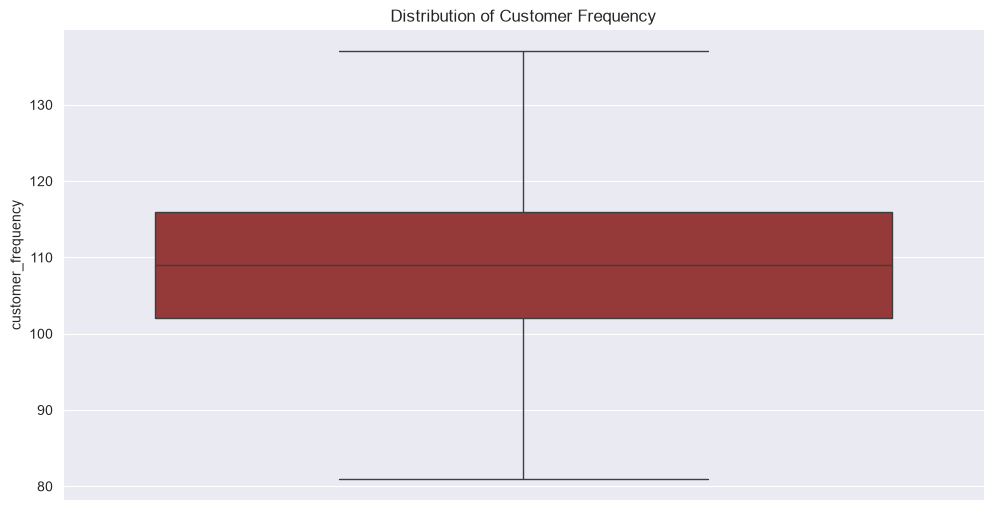

In [ ]:
print(grouped_df['customer_frequency'].value_counts())
sns.catplot(y='customer_frequency', data=grouped_df, kind='box', showfliers=False, height=5, aspect=2, color='brown')
plt.title('Distribution of Customer Frequency')

<class 'pandas.DataFrame'>
RangeIndex: 726 entries, 0 to 725
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   store_key  726 non-null    str  
 1   division   726 non-null    str  
 2   district   726 non-null    str  
 3   upazila    726 non-null    str  
dtypes: str(4)
memory usage: 22.8 KB
None


C:\Users\nourz\AppData\Local\Temp\ipykernel_18420\2343179688.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.relplot(x='division', y='total_amount', data=sorted_grouped_store_df, kind='line', height=5, aspect=2, palette='Set1',marker='o')


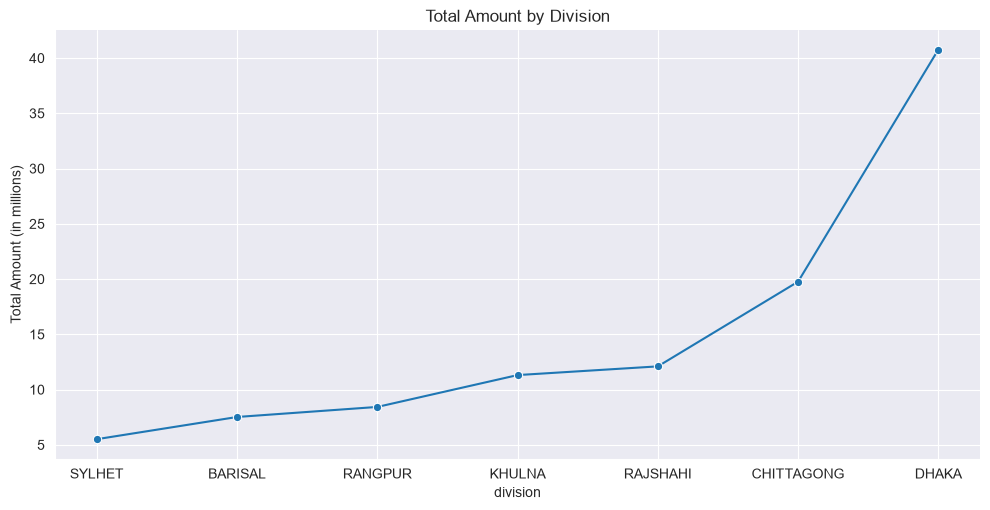

In [ ]:
# EDA store
print(store_df.info())
store_df.dropna(subset=['store_key'], inplace=True)
store_df.isnull().sum()
# merge fact_df1 with store_df 
merge_store_df = fact_df1.merge(store_df, on='store_key', how='left')
grouped_store_df = merge_store_df.groupby('division', as_index=False)['total_amount'].sum()
grouped_store_df['total_amount'] = grouped_store_df['total_amount'] / 1000000
sorted_grouped_store_df = grouped_store_df.sort_values(by='total_amount', ascending=True)
# visualize the trend of total amounts by division
sns.relplot(x='division', y='total_amount', data=sorted_grouped_store_df, kind='line', height=5, aspect=2, palette='Set1',marker='o')
plt.ylabel('Total Amount (in millions)')
plt.title('Total Amount by Division')
plt.ticklabel_format(style='plain', axis='y')
sns.set_style('darkgrid')


<class 'pandas.DataFrame'>
RangeIndex: 264 entries, 0 to 263
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   item_key     264 non-null    str    
 1   item_name    264 non-null    str    
 2   desc         264 non-null    str    
 3   unit_price   264 non-null    float64
 4   man_country  264 non-null    str    
 5   supplier     264 non-null    str    
 6   unit         264 non-null    str    
dtypes: float64(1), str(6)
memory usage: 14.6 KB
None
item_key       0
item_name      0
desc           0
unit_price     0
man_country    0
supplier       0
unit           0
dtype: int64


C:\Users\nourz\AppData\Local\Temp\ipykernel_18420\1317680160.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(y='total_amount', x='desc', data=sorted_grouped_items_df,kind='bar',errorbar=None,height=5, aspect=2, palette='Set1')
C:\Users\nourz\AppData\Local\Temp\ipykernel_18420\1317680160.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(x='man_country' ,data=merged_items_df, kind='count',order=merged_items_df['man_country'].value_counts().index[::-1], height=5, aspect=2, palette='Set1')


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'China'),
  Text(1, 0, 'United States'),
  Text(2, 0, 'Cambodia'),
  Text(3, 0, 'Netherlands'),
  Text(4, 0, 'Lithuania'),
  Text(5, 0, 'Finland'),
  Text(6, 0, 'poland'),
  Text(7, 0, 'Germany'),
  Text(8, 0, 'India'),
  Text(9, 0, 'Bangladesh')])

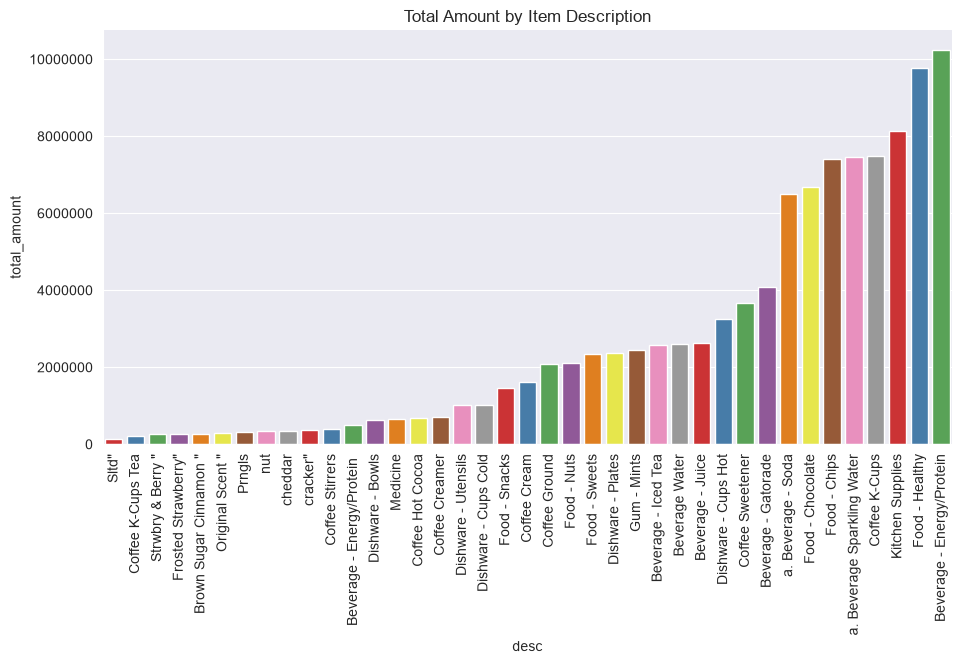

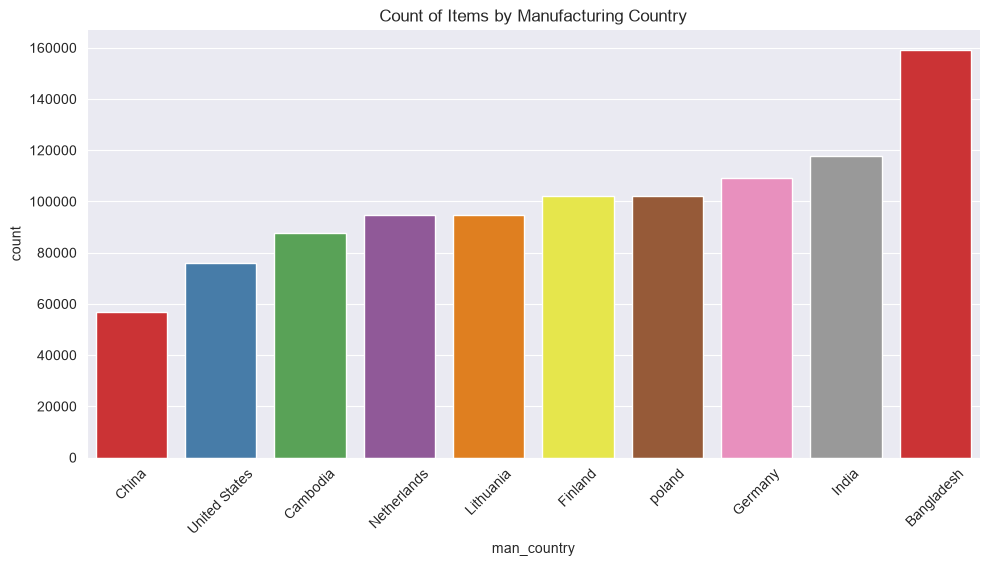

In [ ]:
# EDA items
print(items_df.info())
print(items_df.isnull().sum())
avg_unit_price = items_df['unit_price'].mean()
items_df['unit_price'] = items_df['unit_price'].fillna(avg_unit_price)
items_df = items_df.drop_duplicates(subset=['item_key'])
items_df['item_name'] = items_df['item_name'].replace({'Coca-Cola 12oz': 'Coca-Cola 12 oz', 'Pepsi 12oz': 'Pepsi 12 oz'})
# merge fact_df with items_df and group by item description
merged_items_df = fact_df1.merge(items_df, on='item_key', how='left')
grouped_items_df = merged_items_df.groupby('desc', as_index=False)['total_amount'].sum()
sorted_grouped_items_df = grouped_items_df.sort_values(by='total_amount', ascending=True)
# visualize the trend of total amounts by item description
sns.catplot(y='total_amount', x='desc', data=sorted_grouped_items_df,kind='bar',errorbar=None,height=5, aspect=2, palette='Set1')
plt.title('Total Amount by Item Description')
plt.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation=90)

# replace man_country values 
r=['Food - Sweets', 'Food - Chips', 'Food - Healthy', '6.00', '13.00',
       '15.00', '12.00']
merged_items_df['man_country'] = merged_items_df['man_country'].replace({x: 'Bangladesh' for x in r})
# man country values_count
sns.catplot(x='man_country' ,data=merged_items_df, kind='count',order=merged_items_df['man_country'].value_counts().index[::-1], height=5, aspect=2, palette='Set1')
plt.title('Count of Items by Manufacturing Country')
plt.xticks(rotation=45)
